# 07 — Calendario de recurrencia y distritos

## Calendario del parque

Matriz mes × año del índice armonizado. Sirve para ver en qué meses se concentra la actividad y qué años fueron extremos. La línea punteada marca el inicio de la era con VIIRS.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image

ROOT = Path.cwd()
SERIES = ROOT / "DATOS_PROCESADOS" / "series"
FIGURES = ROOT / "DATOS_PROCESADOS" / "figuras"

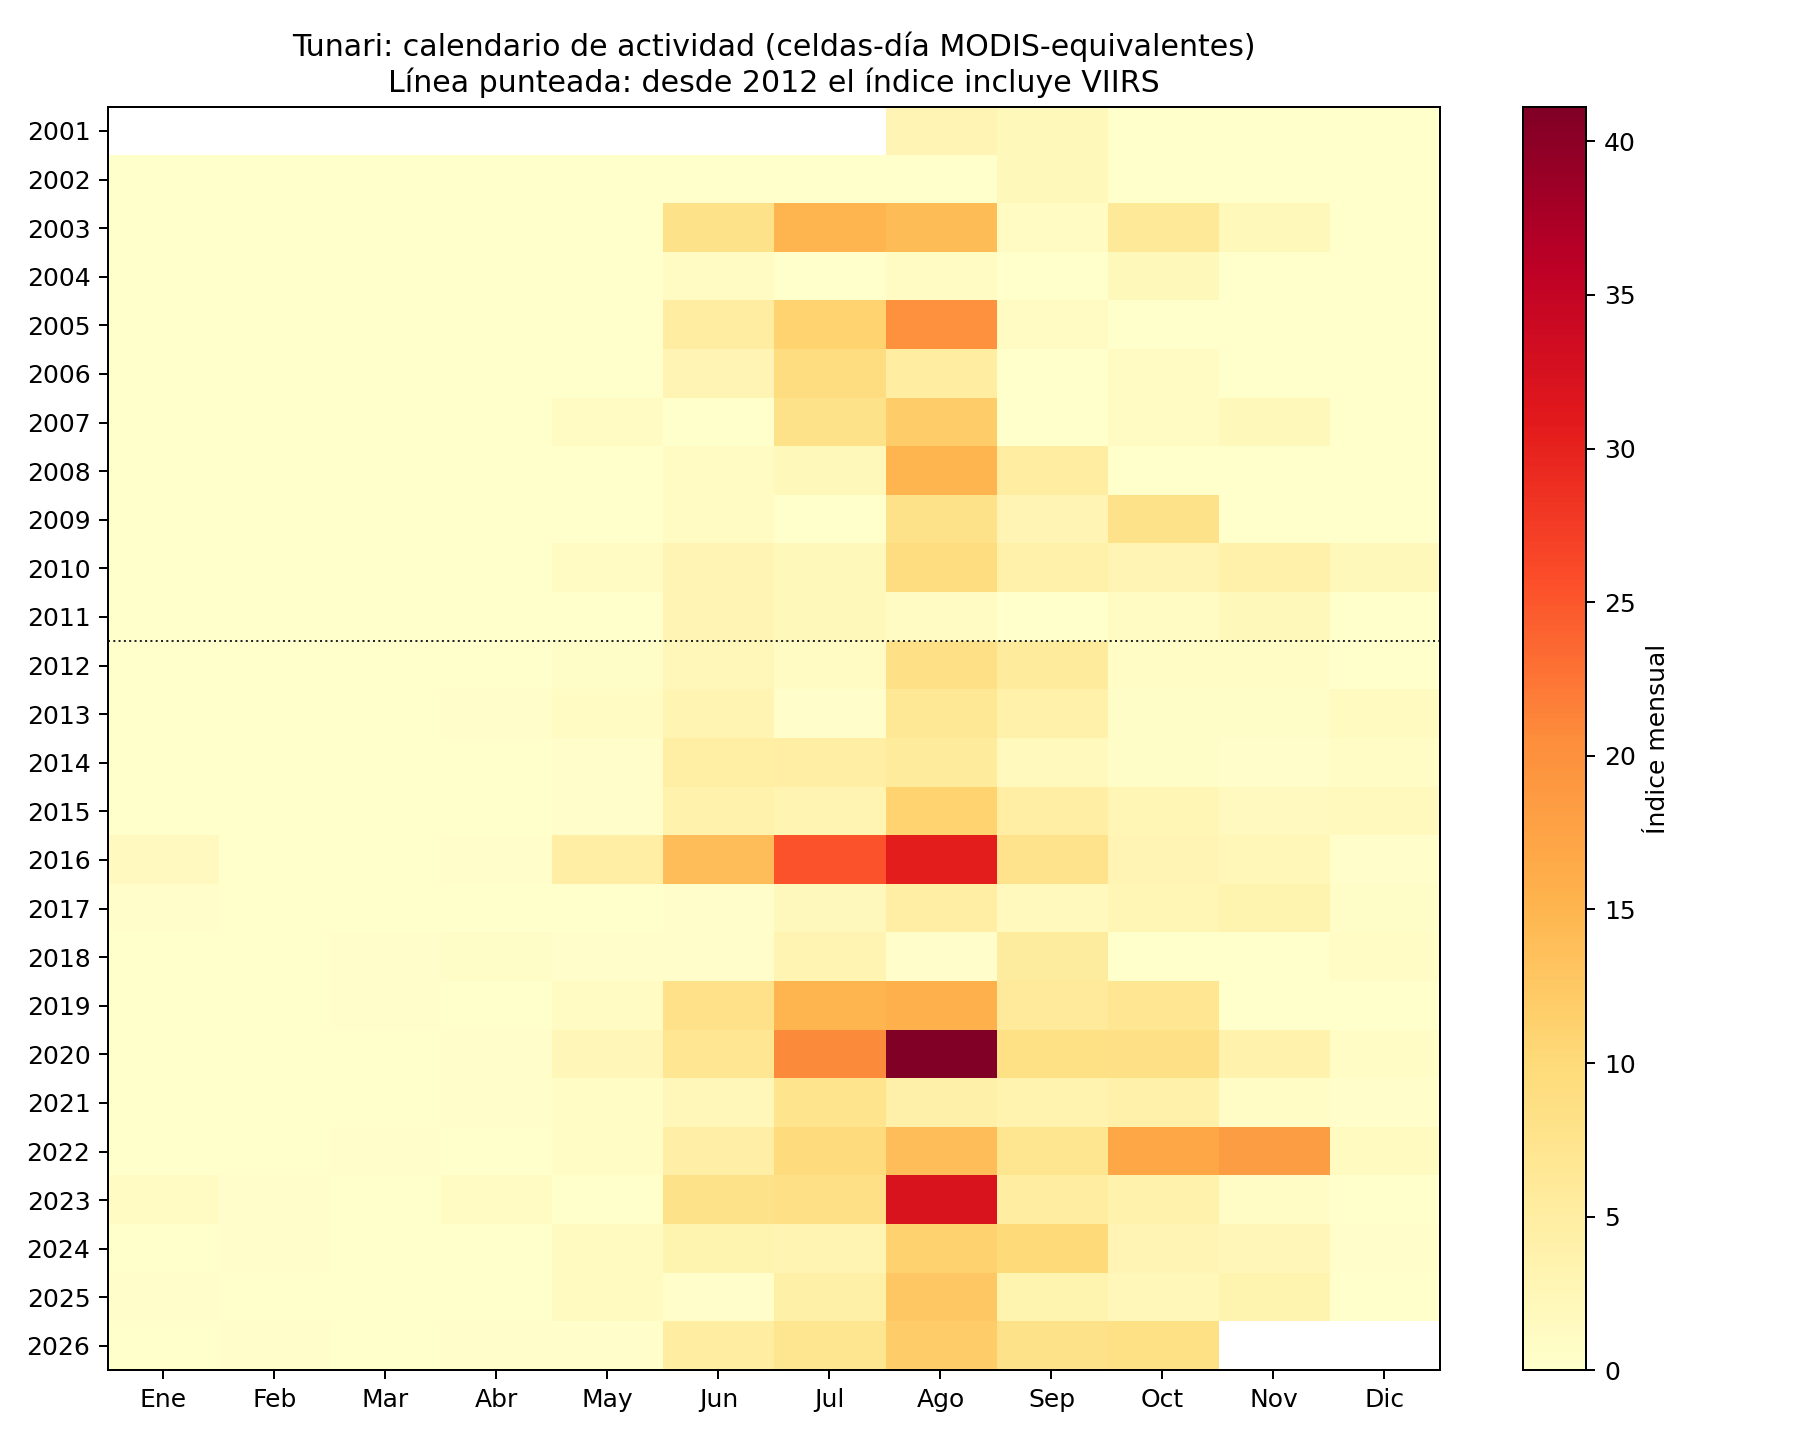

In [2]:
display(Image(filename=str(FIGURES / 'tunari_calendario_mes_anio.png')))

## Distritos de Cochabamba

Cada detección se asigna al distrito que la contiene. **Importante:** los 15 distritos son los del municipio de Cochabamba (capa abierta no oficial). El Parque Nacional Tunari ocupa unos 3.289 km² y se extiende por otros municipios; las detecciones fuera de esos 15 distritos aparecen en una categoría aparte.

Con tan pocas detecciones por distrito **no se calculan alertas**, solo recurrencia (actividad media por mes del año, 2012–2025, con el mismo factor de calibración del parque). Cada mes se promedia entre **sus** años comparables: como la era con VIIRS empieza en febrero de 2012, enero tiene 13 años y los demás meses 14.

In [3]:
resumen = pd.read_csv(SERIES / 'tunari_distritos_resumen.csv')
display(resumen.drop(columns='advertencia'))

,distrito,codigo_distrito,detecciones,celdas_1km_distintas,eventos_candidatos,complejos_candidatos,pct_detecciones_parque,mes_pico,indice_medio_anual_2012_2025
0,Fuera de los 15 distritos de Cochabamba (otros...,fuera,5445,1689,1893,1825,96.4,8,38.73
1,Distrito 13,13,201,45,58,55,3.6,9,1.42


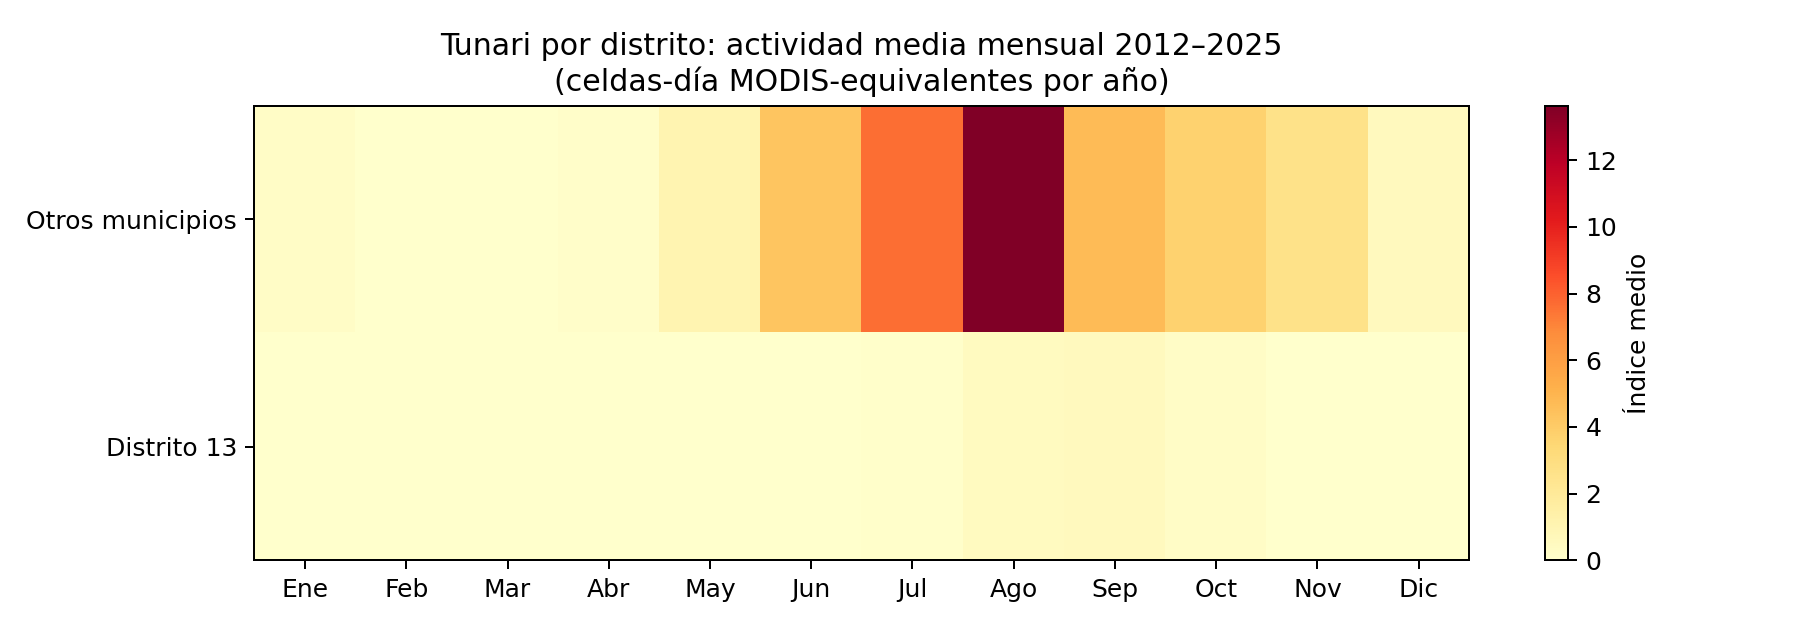

In [4]:
display(Image(filename=str(FIGURES / 'tunari_calendario_distritos.png')))

## Municipios: la unidad común para todo el parque

Los 12 municipios que cruzan el parque (polígonos abiertos de OpenStreetMap, **no oficiales**, simplificados a ~20 m) cubren el 99,8 % de su área, así que permiten asignar prácticamente todas las detecciones. Los distritos de Cochabamba quedan como segundo nivel dentro de ese municipio. `detecciones_por_100km2` usa el área del municipio **dentro del parque**.

In [5]:
resumen_m = pd.read_csv(SERIES / 'tunari_municipios_resumen.csv')
display(resumen_m.drop(columns='advertencia').round(1))

,municipio,detecciones,celdas_1km_distintas,eventos_candidatos,complejos_candidatos,pct_detecciones_parque,area_en_parque_km2,detecciones_por_100km2,mes_pico,indice_medio_anual_2012_2025,meses_evaluables_alerta,meses_vigilancia,meses_candidata_a_verificacion
0,Morochata,1105,355,378,366,19.6,681.0,162.3,8,8.7,183.0,4.0,12.0
1,Sacaba,1067,315,404,381,18.9,420.4,253.8,8,8.3,183.0,1.0,9.0
2,Villa Tunari,617,170,214,206,10.9,251.6,245.3,8,4.2,183.0,3.0,1.0
3,Quillacollo,495,169,165,156,8.8,485.1,102.0,8,3.0,183.0,4.0,4.0
4,Colomi,431,93,148,141,7.6,95.0,453.9,8,3.2,183.0,1.0,5.0
5,Cocapata,411,135,129,124,7.3,317.2,129.6,8,2.7,183.0,1.0,2.0
6,Tiquipaya,404,178,162,159,7.2,292.9,137.9,8,2.9,183.0,0.0,4.0
7,Vinto,359,95,102,101,6.4,168.4,213.2,8,1.8,183.0,0.0,4.0
8,Sipe Sipe,275,113,120,120,4.9,211.1,130.3,8,2.3,NaN,NaN,NaN
9,Tapacarí,203,82,90,90,3.6,173.6,116.9,9,1.3,NaN,NaN,NaN


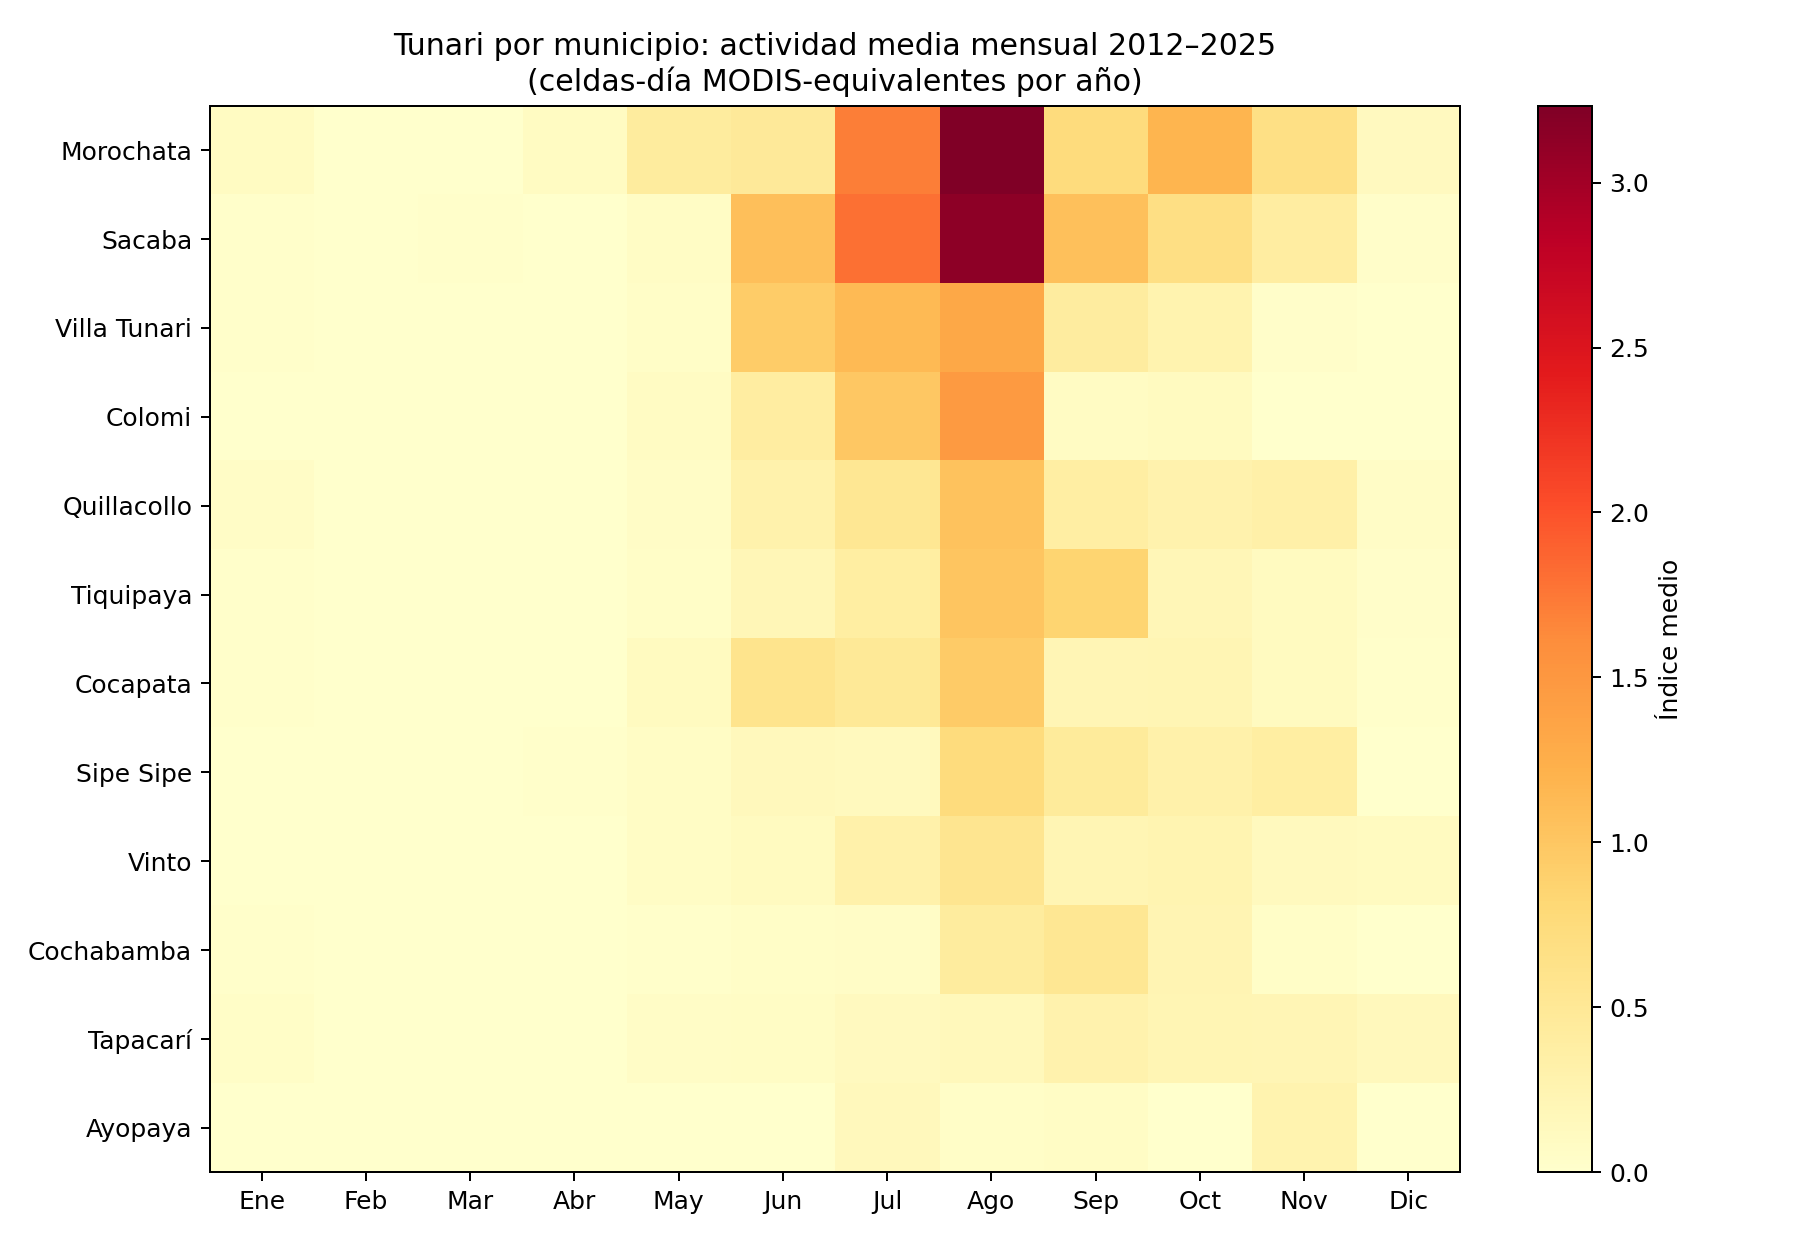

In [6]:
display(Image(filename=str(FIGURES / 'tunari_calendario_municipios.png')))

### Alertas por municipio

Solo se calculan para los municipios con al menos 300 detecciones (en los demás el historial es casi todo ceros). Mismas reglas que en el parque, con VIIRS-SNPP solo desde 2012. Se muestran los meses de 2022 en adelante.

In [7]:
alertas_m = pd.read_csv(SERIES / 'tunari_municipios_alertas_mensuales.csv', parse_dates=['mes_bo'])
marca = ['elevada', 'alta', 'muy_alta']
recientes = alertas_m[alertas_m['anio'].ge(2022) & alertas_m['nivel_alerta'].isin(marca)]
display(recientes[['municipio', 'mes_bo', 'celdas_dia_base', 'veces_mediana_historica', 'probabilidad_exceso', 'nivel_alerta', 'categoria_alerta']].sort_values(['mes_bo', 'municipio']).round(3))

,municipio,mes_bo,celdas_dia_base,veces_mediana_historica,probabilidad_exceso,nivel_alerta,categoria_alerta
252,Cocapata,2022-08-01,8,NaN,0.049,alta,candidata_a_verificacion
858,Morochata,2022-08-01,17,17.000,0.014,alta,candidata_a_verificacion
859,Morochata,2022-09-01,10,4.000,0.052,elevada,vigilancia
860,Morochata,2022-10-01,20,40.000,0.000,muy_alta,candidata_a_verificacion
1466,Sacaba,2022-10-01,8,4.000,0.038,alta,candidata_a_verificacion
861,Morochata,2022-11-01,17,NaN,0.000,muy_alta,candidata_a_verificacion
1164,Quillacollo,2022-11-01,13,NaN,0.000,muy_alta,candidata_a_verificacion
1770,Tiquipaya,2022-11-01,6,NaN,0.002,muy_alta,candidata_a_verificacion
2080,Villa Tunari,2023-06-01,14,14.000,0.000,muy_alta,candidata_a_verificacion
566,Colomi,2023-07-01,12,6.000,0.022,alta,candidata_a_verificacion


## Puntos calientes espaciales (Getis-Ord Gi*)

La recurrencia por celda mira cada celda sola. Gi* pregunta si una celda **y sus vecinas** (radio de 2,5 km) concentran más actividad de la esperable por azar, corrigiendo por pruebas múltiples (FDR 5 %). Variable: celdas-día de VIIRS S-NPP 2013–2025.

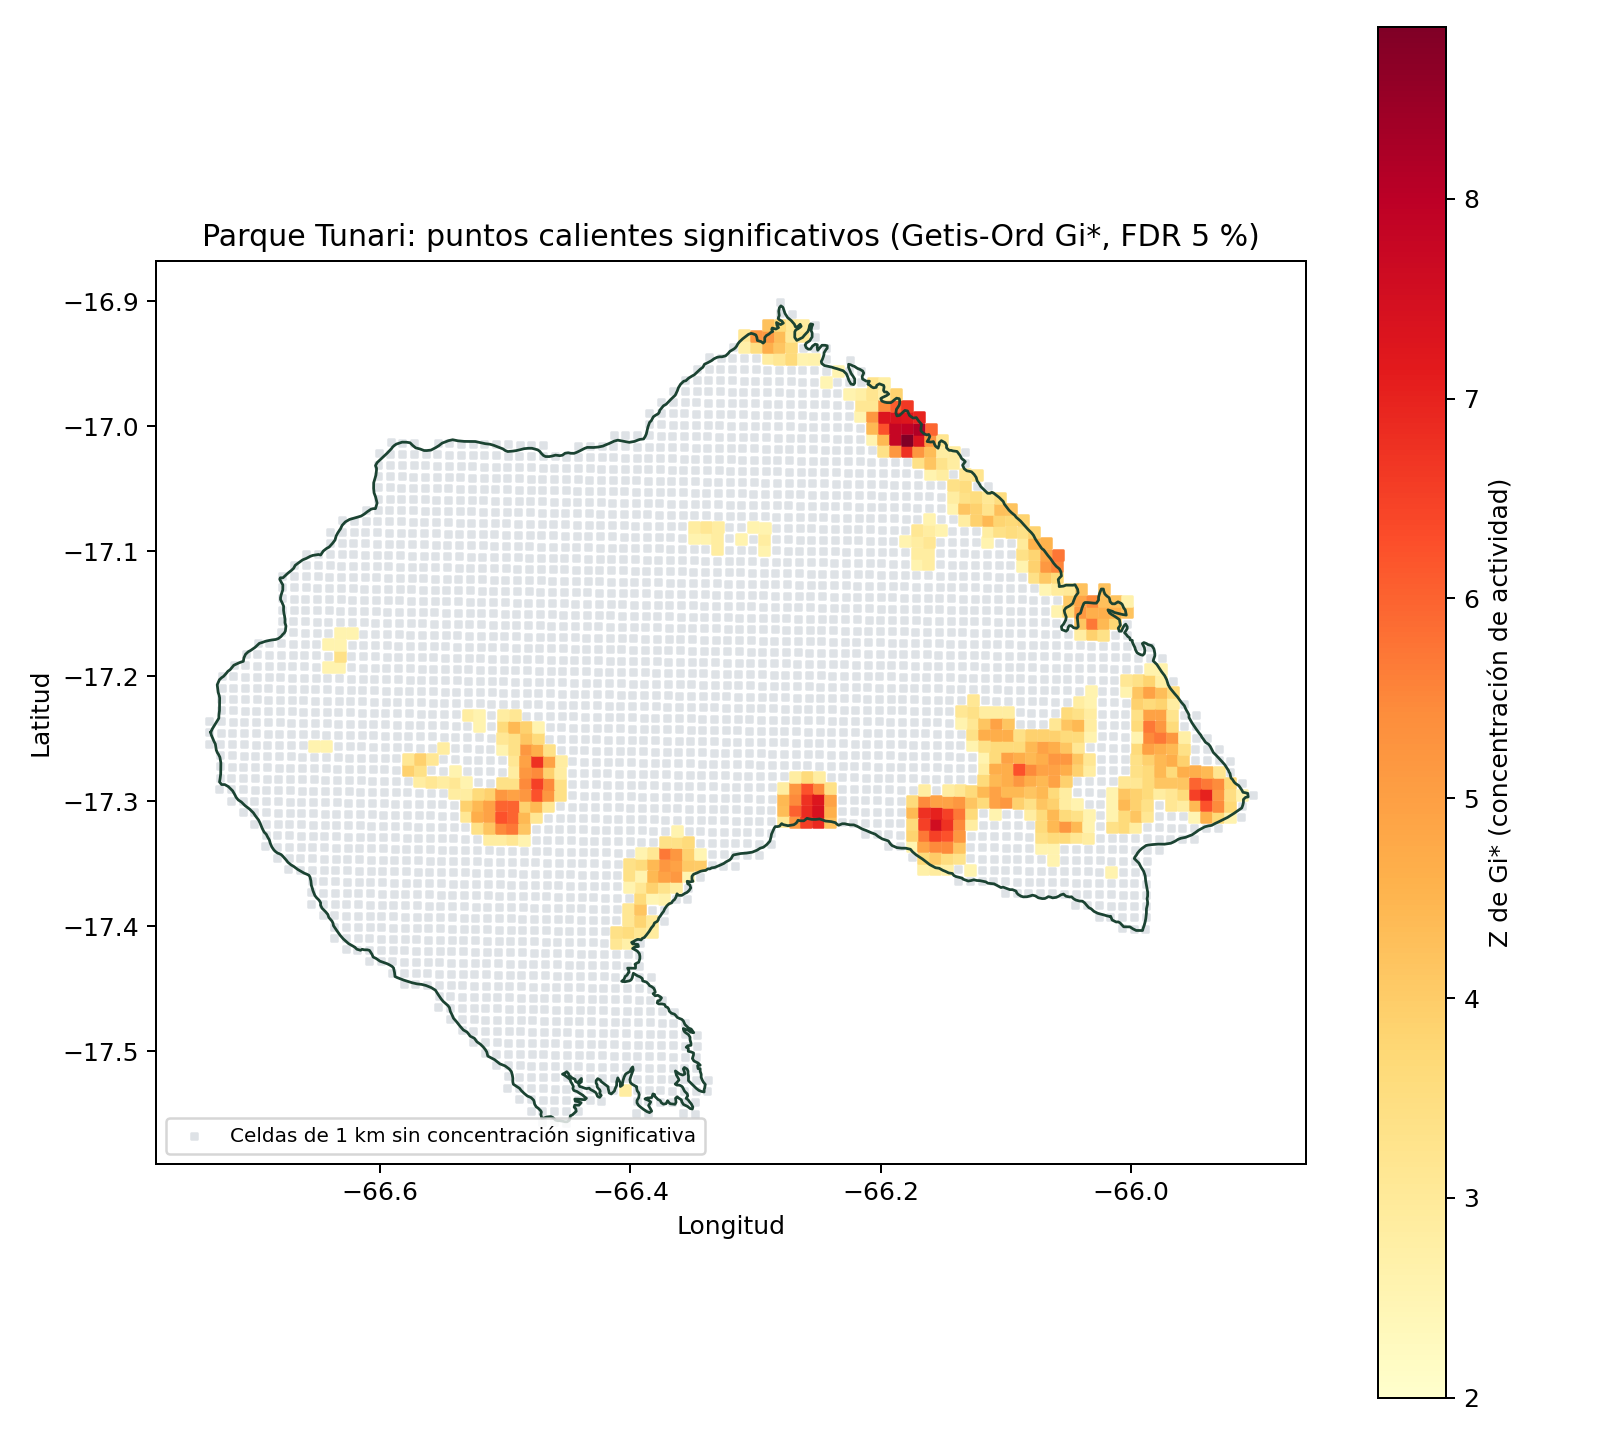

,conglomerado,celdas_1km,celdas_dia_viirs,z_maximo,lon_centro,lat_centro,municipio_principal
0,2,147,193.0,7.55,-66.10,-17.29,Sacaba
1,10,110,149.0,8.86,-66.12,-17.06,Villa Tunari
2,6,89,122.0,7.03,-65.97,-17.27,Colomi
3,4,77,97.0,6.77,-66.50,-17.28,Morochata
4,1,42,53.0,5.72,-66.38,-17.37,Vinto
5,5,23,36.0,7.43,-66.26,-17.30,Quillacollo
6,15,20,27.0,5.20,-66.28,-16.93,Cocapata
7,11,11,15.0,3.11,-66.17,-17.09,Tiquipaya
8,13,5,11.0,2.84,-66.30,-17.09,Quillacollo
9,12,7,7.0,3.11,-66.34,-17.09,Quillacollo


In [8]:
display(Image(filename=str(FIGURES / 'tunari_puntos_calientes_gi.png')))
cong = pd.read_csv(SERIES / 'tunari_conglomerados_gi.csv')
display(cong.drop(columns='advertencia').round(2).head(10))

## Límites y precauciones

- Los límites municipales son una referencia abierta, no oficial; deben validarse con el INE o el GAM antes de usos institucionales.
- Una detección cerca de un límite puede quedar en el municipio vecino (la geometría está simplificada).
- Las alertas por municipio son candidatas a verificación, con los mismos umbrales de prototipo del parque.